# PRCP-1023 — Johns Hopkins COVID-19 Data Analysis and Forecasting

**Domain:** Healthcare

## Project Objective

This single Jupyter Notebook completes the three tasks in the project statement:

1. Prepare a complete data analysis report on the COVID-19 data.
2. Fix a prediction period and build predictive models to forecast COVID-19 confirmed cases and deaths for a specific country/region.
3. Provide preparation suggestions for the health department based on the model forecasts.

The notebook also includes:
- Data cleaning and preprocessing
- Exploratory Data Analysis
- Feature engineering
- Multiple-model comparison
- Test-set evaluation
- 7-day future forecasting
- Production-model selection based on test performance
- Challenges and solutions
- Final conclusion


## Problem Statement

### Task 1
Prepare a complete data analysis report on the given data.

### Task 2
Fix a period for prediction of confirmed cases/deaths and create a predictive model to forecast COVID-19 cases based on past cases for a specific country or region.

### Task 3
Make suggestions to the government health department of the country/region for preparation based on the predictions.

### Model Comparison Report
Report the performance of multiple models on the data and identify the model selected for production forecasting based on the test-set metric.

### Challenges Report
Document challenges faced in the data and the techniques/reasoning used to handle them.

All tasks are implemented in this single Jupyter Notebook.


## Dataset Description

The project statement describes a daily-updating version of the COVID-19 Data Repository from the Center for Systems Science and Engineering (CSSE) at Johns Hopkins University.

The supplied dataset folder contains these three files:

- `time_series_covid19_confirmed_global`
- `time_series_covid19_deaths_global`
- `time_series_covid19_recovered_global`

The Johns Hopkins time-series files use geographic columns followed by date columns. The notebook converts the wide time-series data into a country/date format suitable for analysis and forecasting.

The project statement notes that the convenient data representation uses daily change rather than cumulative totals. This notebook also calculates daily changes from the supplied cumulative time-series data so that the forecasting target is directly interpretable as new daily cases/deaths.


## 1. Import Required Libraries

In [1]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

print("Libraries imported successfully")


Libraries imported successfully


## 2. Locate the Three Dataset Files

The code below searches the current Jupyter Notebook folder automatically, so you do not have to rename the downloaded files.

It supports both `.csv` files and files with the same names but no visible extension.


In [2]:
def find_dataset(keyword):
    patterns = [
        f"*{keyword}*global*.csv",
        f"*{keyword}*global*",
        f"*{keyword}*.csv",
        f"*{keyword}*"
    ]

    matches = []
    for pattern in patterns:
        matches.extend(glob.glob(pattern))

    # Remove duplicates while preserving order
    matches = list(dict.fromkeys(matches))

    # Ignore the notebook itself or unrelated files
    matches = [
        f for f in matches
        if os.path.isfile(f)
        and not f.endswith(".ipynb")
    ]

    if not matches:
        raise FileNotFoundError(
            f"Could not find a dataset file containing '{keyword}'. "
            "Make sure the three downloaded files are in the same folder as this notebook."
        )

    return matches[0]

confirmed_file = find_dataset("confirmed")
deaths_file = find_dataset("deaths")
recovered_file = find_dataset("recovered")

print("Confirmed file :", confirmed_file)
print("Deaths file    :", deaths_file)
print("Recovered file :", recovered_file)


Confirmed file : time_series_covid19_confirmed_global.csv
Deaths file    : time_series_covid19_deaths_global.csv
Recovered file : time_series_covid19_recovered_global.csv


## 3. Load the Datasets

In [3]:
confirmed = pd.read_csv(confirmed_file)
deaths = pd.read_csv(deaths_file)
recovered = pd.read_csv(recovered_file)

print("Confirmed shape :", confirmed.shape)
print("Deaths shape    :", deaths.shape)
print("Recovered shape :", recovered.shape)


Confirmed shape : (266, 248)
Deaths shape    : (266, 248)
Recovered shape : (253, 248)


## 4. Initial Data Inspection

In [4]:
print("CONFIRMED")
display(confirmed.head())

print("DEATHS")
display(deaths.head())

print("RECOVERED")
display(recovered.head())


CONFIRMED


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,38641,38716,38772,38815,38855,38872,38883,38919,39044,39074
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,11185,11353,11520,11672,11816,11948,12073,12226,12385,12535
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,48007,48254,48496,48734,48966,49194,49413,49623,49826,50023
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,1344,1344,1438,1438,1483,1483,1564,1564,1564,1681
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,3335,3388,3439,3569,3675,3789,3848,3901,3991,4117


DEATHS


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,1420,1420,1425,1426,1436,1436,1437,1437,1441,1444
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,330,334,338,340,343,347,353,358,362,364
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,1605,1612,1620,1632,1645,1654,1659,1665,1672,1679
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,53,53,53,53,53,53,53,53,53,53
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,132,134,136,139,143,144,147,147,152,154


RECOVERED


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,31234,31638,32073,32098,32503,32505,32576,32576,32576,32576
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,6494,6569,6615,6668,6733,6788,6831,6888,6940,6995
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,33875,34037,34204,34385,34517,34675,34818,34923,35047,35180
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,943,943,945,945,1054,1054,1164,1164,1164,1199
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,1289,1301,1324,1332,1401,1405,1443,1445,1445,1449


In [5]:
print("Confirmed columns:")
print(confirmed.columns.tolist())

print("\nDeaths columns:")
print(deaths.columns.tolist())

print("\nRecovered columns:")
print(recovered.columns.tolist())


Confirmed columns:
['Province/State', 'Country/Region', 'Lat', 'Long', '1/22/20', '1/23/20', '1/24/20', '1/25/20', '1/26/20', '1/27/20', '1/28/20', '1/29/20', '1/30/20', '1/31/20', '2/1/20', '2/2/20', '2/3/20', '2/4/20', '2/5/20', '2/6/20', '2/7/20', '2/8/20', '2/9/20', '2/10/20', '2/11/20', '2/12/20', '2/13/20', '2/14/20', '2/15/20', '2/16/20', '2/17/20', '2/18/20', '2/19/20', '2/20/20', '2/21/20', '2/22/20', '2/23/20', '2/24/20', '2/25/20', '2/26/20', '2/27/20', '2/28/20', '2/29/20', '3/1/20', '3/2/20', '3/3/20', '3/4/20', '3/5/20', '3/6/20', '3/7/20', '3/8/20', '3/9/20', '3/10/20', '3/11/20', '3/12/20', '3/13/20', '3/14/20', '3/15/20', '3/16/20', '3/17/20', '3/18/20', '3/19/20', '3/20/20', '3/21/20', '3/22/20', '3/23/20', '3/24/20', '3/25/20', '3/26/20', '3/27/20', '3/28/20', '3/29/20', '3/30/20', '3/31/20', '4/1/20', '4/2/20', '4/3/20', '4/4/20', '4/5/20', '4/6/20', '4/7/20', '4/8/20', '4/9/20', '4/10/20', '4/11/20', '4/12/20', '4/13/20', '4/14/20', '4/15/20', '4/16/20', '4/17/20',

In [6]:
print("Missing values in Confirmed:")
display(confirmed.isnull().sum())

print("Missing values in Deaths:")
display(deaths.isnull().sum())

print("Missing values in Recovered:")
display(recovered.isnull().sum())


Missing values in Confirmed:


Province/State    185
Country/Region      0
Lat                 0
Long                0
1/22/20             0
                 ... 
9/17/20             0
9/18/20             0
9/19/20             0
9/20/20             0
9/21/20             0
Length: 248, dtype: int64

Missing values in Deaths:


Province/State    185
Country/Region      0
Lat                 0
Long                0
1/22/20             0
                 ... 
9/17/20             0
9/18/20             0
9/19/20             0
9/20/20             0
9/21/20             0
Length: 248, dtype: int64

Missing values in Recovered:


Province/State    186
Country/Region      0
Lat                 0
Long                0
1/22/20             0
                 ... 
9/17/20             0
9/18/20             0
9/19/20             0
9/20/20             0
9/21/20             0
Length: 248, dtype: int64

In [7]:
print("Duplicate rows:")
print("Confirmed :", confirmed.duplicated().sum())
print("Deaths    :", deaths.duplicated().sum())
print("Recovered :", recovered.duplicated().sum())


Duplicate rows:
Confirmed : 0
Deaths    : 0
Recovered : 0


## 5. Data Cleaning

The geographic columns are retained. Duplicate rows are removed. Province/state values can be missing in the global country-level files, so missing province/state values are not treated as an error.

The analysis is performed at country level, so province/state rows are later aggregated by country and date.


In [8]:
confirmed = confirmed.drop_duplicates().copy()
deaths = deaths.drop_duplicates().copy()
recovered = recovered.drop_duplicates().copy()

# Remove possible UTF-8 BOM/whitespace from column names
confirmed.columns = [str(c).replace("\ufeff", "").strip() for c in confirmed.columns]
deaths.columns = [str(c).replace("\ufeff", "").strip() for c in deaths.columns]
recovered.columns = [str(c).replace("\ufeff", "").strip() for c in recovered.columns]

print("Cleaning completed")


Cleaning completed


## 6. Identify Date Columns

The original files contain geographic metadata columns followed by dates. The helper below identifies columns that can be interpreted as dates.


In [9]:
id_columns = ["Province/State", "Country/Region", "Lat", "Long"]

def get_date_columns(df):
    date_cols = []
    for col in df.columns:
        if col in id_columns:
            continue
        try:
            parsed = pd.to_datetime(col, errors="raise")
            date_cols.append(col)
        except:
            pass
    return date_cols

confirmed_date_columns = get_date_columns(confirmed)
deaths_date_columns = get_date_columns(deaths)
recovered_date_columns = get_date_columns(recovered)

print("Confirmed date columns:", len(confirmed_date_columns))
print("Deaths date columns   :", len(deaths_date_columns))
print("Recovered date columns:", len(recovered_date_columns))

print("\nFirst five dates:")
print(confirmed_date_columns[:5])
print("\nLast five dates:")
print(confirmed_date_columns[-5:])


Confirmed date columns: 244
Deaths date columns   : 244
Recovered date columns: 244

First five dates:
['1/22/20', '1/23/20', '1/24/20', '1/25/20', '1/26/20']

Last five dates:
['9/17/20', '9/18/20', '9/19/20', '9/20/20', '9/21/20']


## 7. Convert Wide Data to Long Format

Wide format stores every date as a separate column.

Long format stores one observation per country/province/date. This format is easier to use for time-series analysis and machine learning.


In [10]:
confirmed_long = confirmed.melt(
    id_vars=[c for c in id_columns if c in confirmed.columns],
    value_vars=confirmed_date_columns,
    var_name="Date",
    value_name="Confirmed"
)

deaths_long = deaths.melt(
    id_vars=[c for c in id_columns if c in deaths.columns],
    value_vars=deaths_date_columns,
    var_name="Date",
    value_name="Deaths"
)

recovered_long = recovered.melt(
    id_vars=[c for c in id_columns if c in recovered.columns],
    value_vars=recovered_date_columns,
    var_name="Date",
    value_name="Recovered"
)

for df in [confirmed_long, deaths_long, recovered_long]:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    for col in ["Confirmed", "Deaths", "Recovered"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

print("Long-format data created")
display(confirmed_long.head())


Long-format data created


,Province/State,Country/Region,Lat,Long,Date,Confirmed
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0
1,NaN,Albania,41.15330,20.168300,2020-01-22,0
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0


## 8. Country-Level Aggregation

Some countries can contain more than one province/state record. Therefore, all province/state records are summed for each country and date.


In [11]:
confirmed_country = (
    confirmed_long
    .groupby(["Country/Region", "Date"], as_index=False)["Confirmed"]
    .sum()
)

deaths_country = (
    deaths_long
    .groupby(["Country/Region", "Date"], as_index=False)["Deaths"]
    .sum()
)

recovered_country = (
    recovered_long
    .groupby(["Country/Region", "Date"], as_index=False)["Recovered"]
    .sum()
)

print("Country-level confirmed:", confirmed_country.shape)
print("Country-level deaths   :", deaths_country.shape)
print("Country-level recovered:", recovered_country.shape)


Country-level confirmed: (45872, 3)
Country-level deaths   : (45872, 3)
Country-level recovered: (45872, 3)


# 9. Exploratory Data Analysis

The analysis first examines the latest available date and the countries with the largest confirmed-case and death totals.


In [12]:
latest_date = confirmed_country["Date"].max()

print("Latest available date:", latest_date)


Latest available date: 2020-09-21 00:00:00


In [13]:
latest_confirmed = (
    confirmed_country[confirmed_country["Date"] == latest_date]
    .sort_values("Confirmed", ascending=False)
)

display(latest_confirmed.head(10))


,Country/Region,Date,Confirmed
42699,US,2020-09-21,6856884
19519,India,2020-09-21,5487580
5855,Brazil,2020-09-21,4558040
34403,Russia,2020-09-21,1105048
9271,Colombia,2020-09-21,770435
32939,Peru,2020-09-21,768895
27815,Mexico,2020-09-21,700580
38795,Spain,2020-09-21,671468
38307,South Africa,2020-09-21,661936
1707,Argentina,2020-09-21,640147


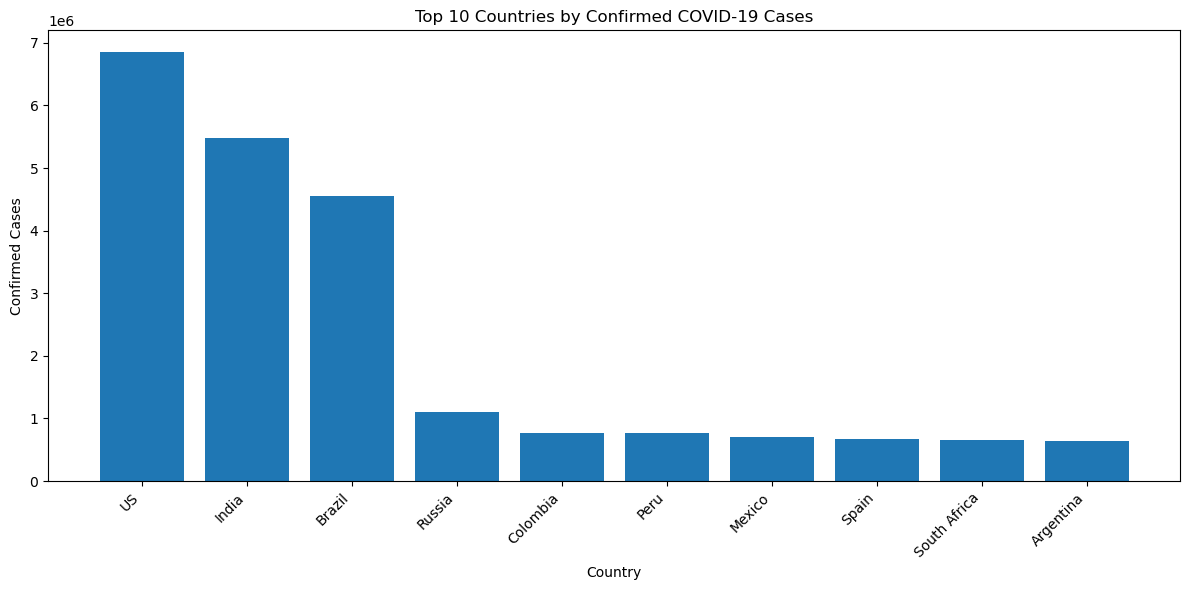

In [14]:
top10_confirmed = latest_confirmed.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10_confirmed["Country/Region"], top10_confirmed["Confirmed"])
plt.title("Top 10 Countries by Confirmed COVID-19 Cases")
plt.xlabel("Country")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [15]:
latest_deaths = (
    deaths_country[deaths_country["Date"] == latest_date]
    .sort_values("Deaths", ascending=False)
)

display(latest_deaths.head(10))


,Country/Region,Date,Deaths
42699,US,2020-09-21,199865
5855,Brazil,2020-09-21,137272
19519,India,2020-09-21,87882
27815,Mexico,2020-09-21,73697
43675,United Kingdom,2020-09-21,41877
20983,Italy,2020-09-21,35724
32939,Peru,2020-09-21,31369
15371,France,2020-09-21,31346
38795,Spain,2020-09-21,30663
20007,Iran,2020-09-21,24478


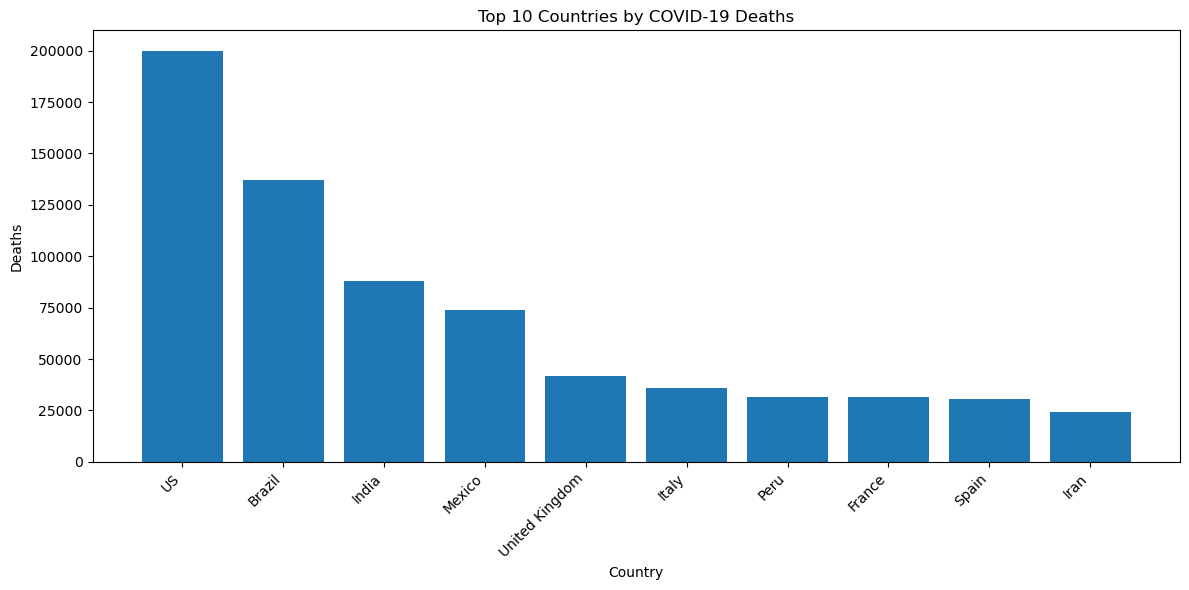

In [16]:
top10_deaths = latest_deaths.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10_deaths["Country/Region"], top10_deaths["Deaths"])
plt.title("Top 10 Countries by COVID-19 Deaths")
plt.xlabel("Country")
plt.ylabel("Deaths")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 10. Selected Country for Forecasting

The project requires a specific country or region. India is selected for this notebook.

If your instructor wants another country, change the value in the next code cell.


In [17]:
country = "India"

available_countries = sorted(
    confirmed_country["Country/Region"].dropna().unique()
)

if country not in available_countries:
    raise ValueError(
        f"{country} was not found in the dataset. "
        "Check the country names displayed in available_countries."
    )

print("Selected country:", country)


Selected country: India


In [18]:
india_confirmed = confirmed_country[
    confirmed_country["Country/Region"] == country
].sort_values("Date").copy()

india_deaths = deaths_country[
    deaths_country["Country/Region"] == country
].sort_values("Date").copy()

india_recovered = recovered_country[
    recovered_country["Country/Region"] == country
].sort_values("Date").copy()

print("Confirmed rows:", len(india_confirmed))
print("Deaths rows:", len(india_deaths))
print("Recovered rows:", len(india_recovered))


Confirmed rows: 244
Deaths rows: 244
Recovered rows: 244


## 11. India Confirmed Cases Trend

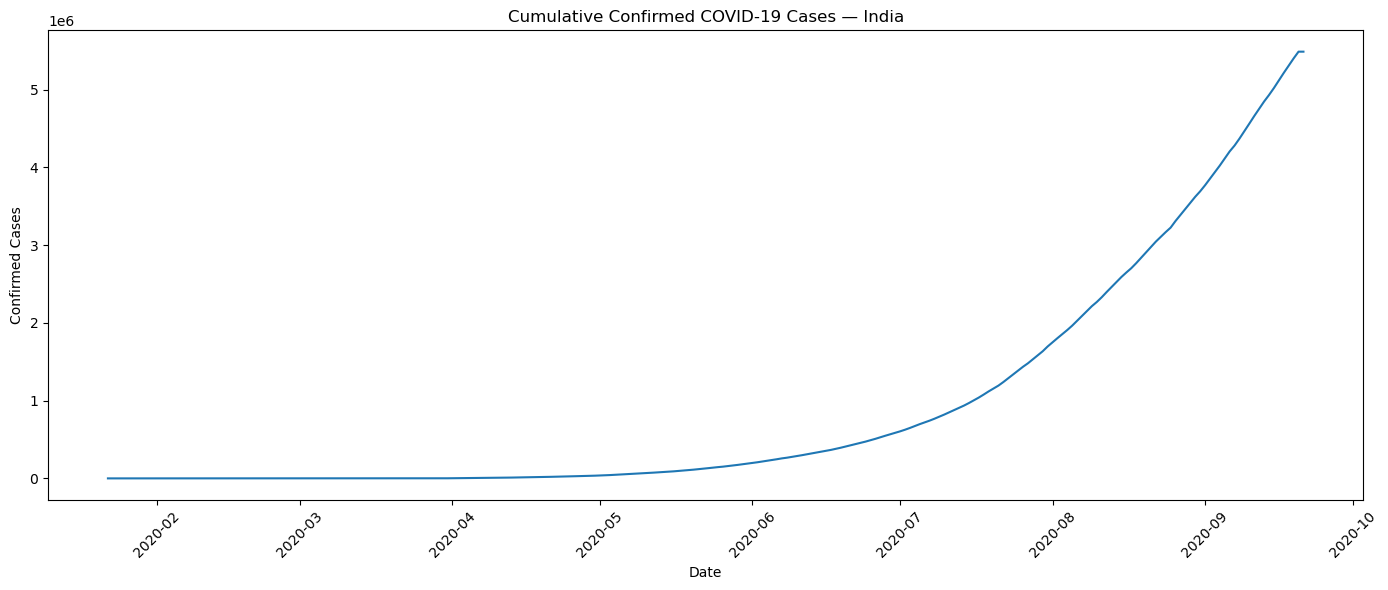

In [19]:
plt.figure(figsize=(14, 6))
plt.plot(india_confirmed["Date"], india_confirmed["Confirmed"])
plt.title(f"Cumulative Confirmed COVID-19 Cases — {country}")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 12. India Deaths Trend

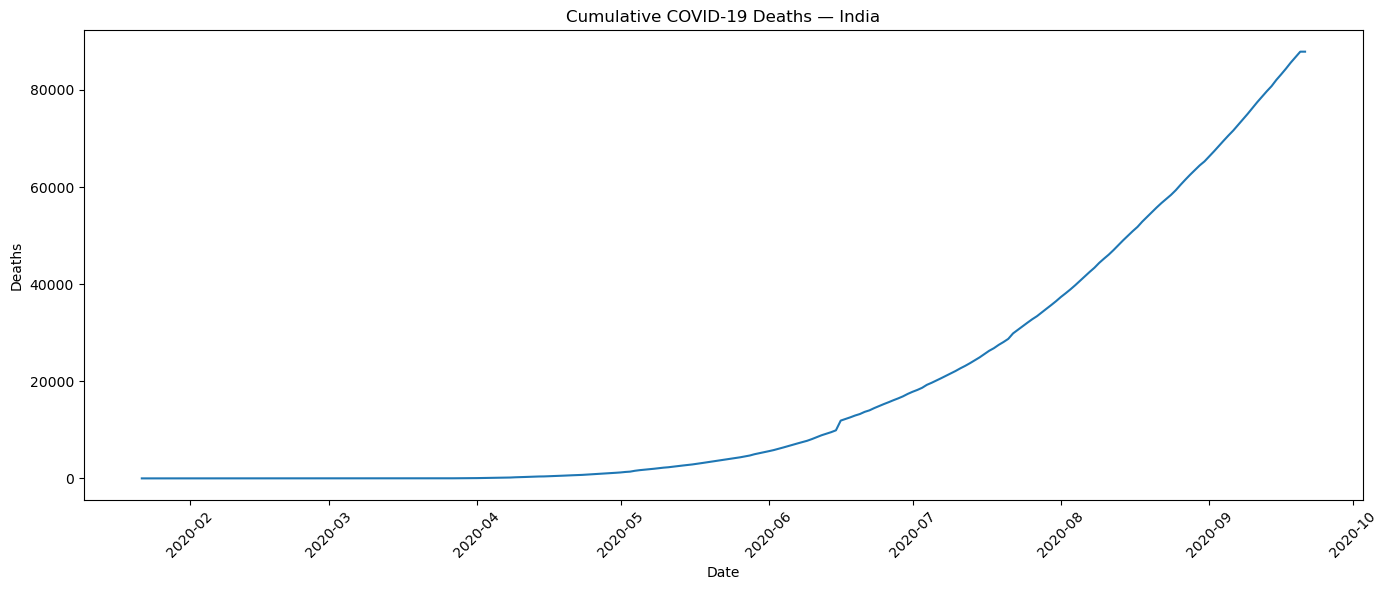

In [20]:
plt.figure(figsize=(14, 6))
plt.plot(india_deaths["Date"], india_deaths["Deaths"])
plt.title(f"Cumulative COVID-19 Deaths — {country}")
plt.xlabel("Date")
plt.ylabel("Deaths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 13. India Recovered Cases Trend

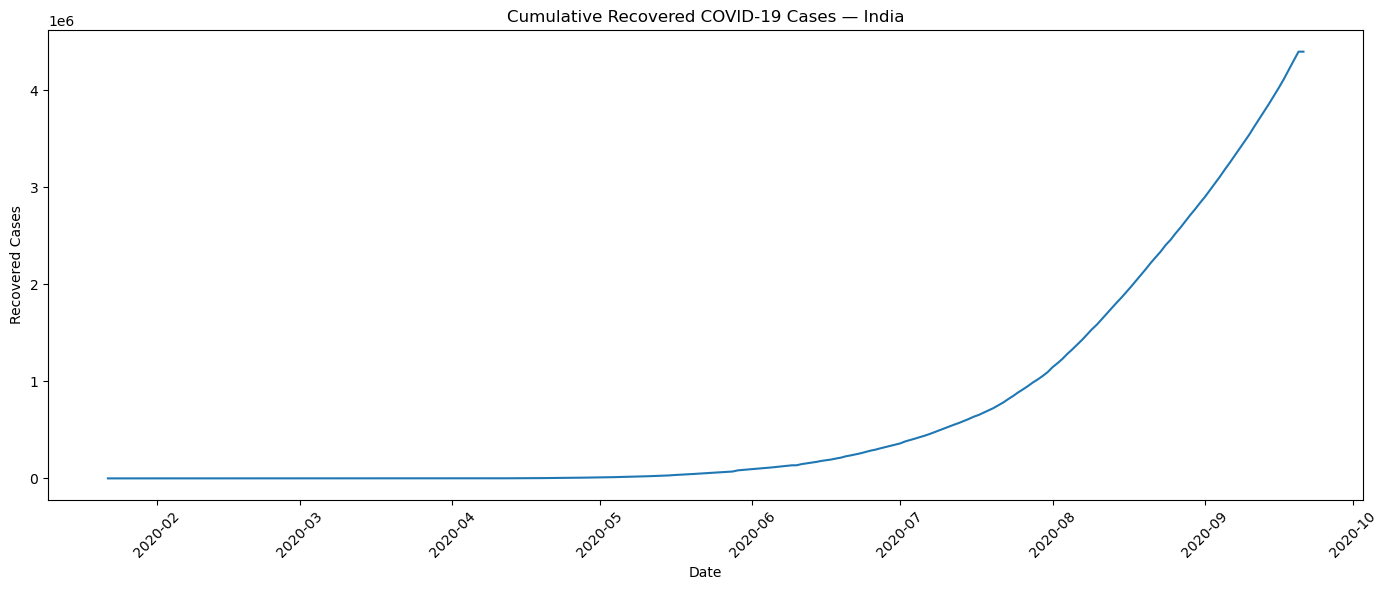

In [21]:
plt.figure(figsize=(14, 6))
plt.plot(india_recovered["Date"], india_recovered["Recovered"])
plt.title(f"Cumulative Recovered COVID-19 Cases — {country}")
plt.xlabel("Date")
plt.ylabel("Recovered Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 14. Daily Cases and Daily Deaths

The supplied time-series values are cumulative. Daily values are calculated using the difference between consecutive dates.

Negative differences can occur in historical surveillance data because previously reported totals can be corrected. For forecasting, negative daily values are replaced with zero because the target represents newly reported cases/deaths.


In [22]:
india_confirmed["Daily_Cases"] = (
    india_confirmed["Confirmed"].diff().fillna(0)
)

india_deaths["Daily_Deaths"] = (
    india_deaths["Deaths"].diff().fillna(0)
)

india_confirmed["Daily_Cases"] = india_confirmed["Daily_Cases"].clip(lower=0)
india_deaths["Daily_Deaths"] = india_deaths["Daily_Deaths"].clip(lower=0)

print("Daily cases summary:")
display(india_confirmed["Daily_Cases"].describe())

print("Daily deaths summary:")
display(india_deaths["Daily_Deaths"].describe())


Daily cases summary:


count      244.000000
mean     22490.081967
std      30070.677207
min          0.000000
25%         37.750000
50%       6172.500000
75%      41433.000000
max      97894.000000
Name: Daily_Cases, dtype: float64

Daily deaths summary:


count     244.000000
mean      360.176230
std       414.167356
min         0.000000
25%         1.000000
50%       149.000000
75%       691.500000
max      2003.000000
Name: Daily_Deaths, dtype: float64

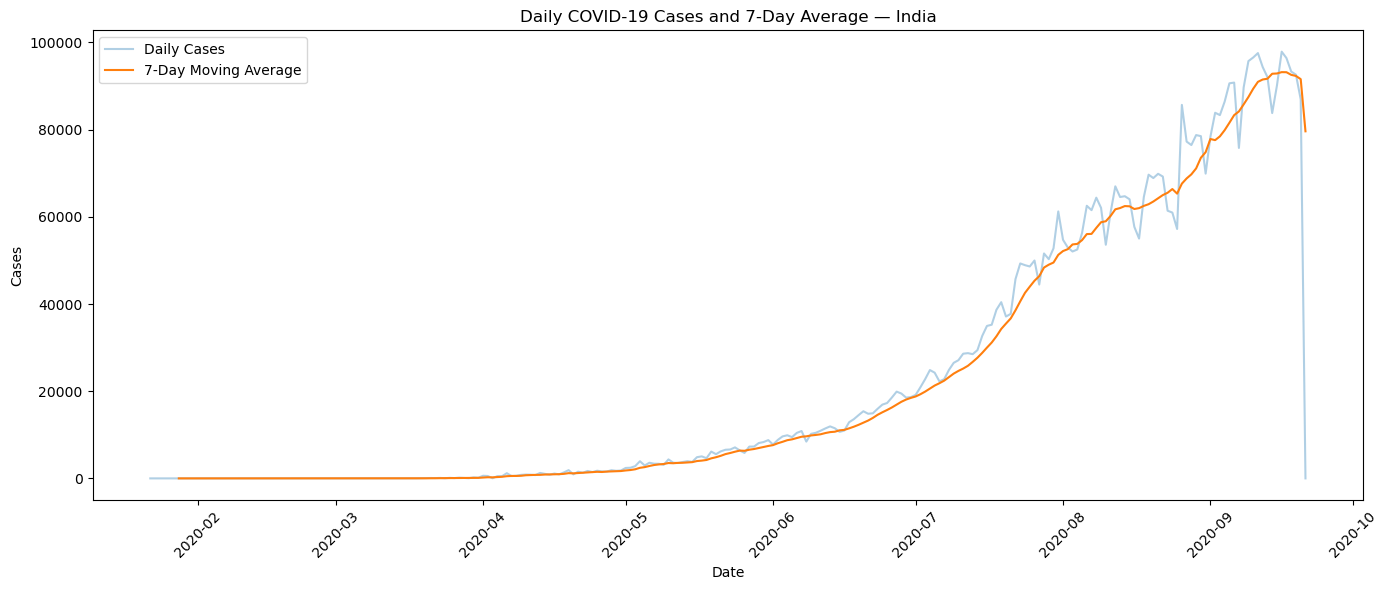

In [23]:
india_confirmed["7_Day_Average"] = (
    india_confirmed["Daily_Cases"].rolling(7).mean()
)

plt.figure(figsize=(14, 6))
plt.plot(
    india_confirmed["Date"],
    india_confirmed["Daily_Cases"],
    alpha=0.35,
    label="Daily Cases"
)
plt.plot(
    india_confirmed["Date"],
    india_confirmed["7_Day_Average"],
    label="7-Day Moving Average"
)
plt.title(f"Daily COVID-19 Cases and 7-Day Average — {country}")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


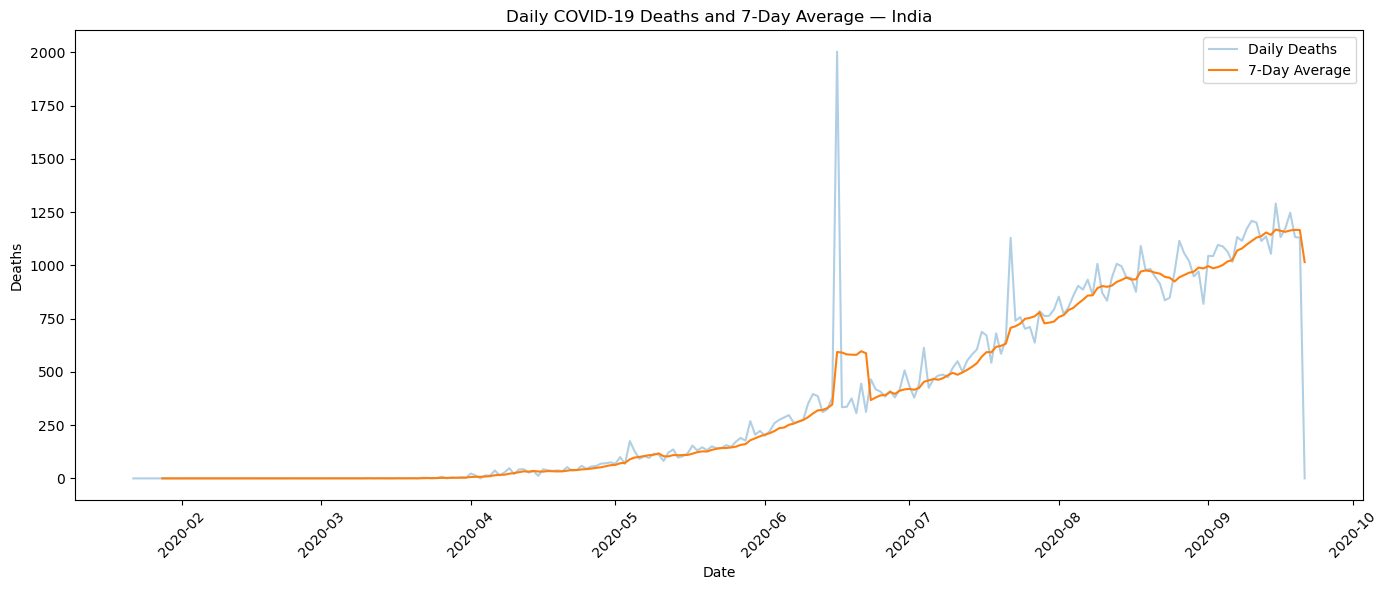

In [24]:
india_deaths["7_Day_Average"] = (
    india_deaths["Daily_Deaths"].rolling(7).mean()
)

plt.figure(figsize=(14, 6))
plt.plot(
    india_deaths["Date"],
    india_deaths["Daily_Deaths"],
    alpha=0.35,
    label="Daily Deaths"
)
plt.plot(
    india_deaths["Date"],
    india_deaths["7_Day_Average"],
    label="7-Day Average"
)
plt.title(f"Daily COVID-19 Deaths and 7-Day Average — {country}")
plt.xlabel("Date")
plt.ylabel("Deaths")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 15. Forecasting Plan

### Fixed prediction period

The forecasting horizon is fixed at **7 days**.

### Target variables

Two forecasting tasks are performed:

1. Daily confirmed COVID-19 cases
2. Daily COVID-19 deaths

### Features

The models use historical lag values:

- Lag 1 — previous day
- Lag 2 — two days earlier
- Lag 3 — three days earlier
- Lag 7 — one week earlier

This preserves chronological order and avoids using future observations as predictors.


In [25]:
FORECAST_DAYS = 7

LAGS = [1, 2, 3, 7]

print("Forecast period:", FORECAST_DAYS, "days")
print("Lag features:", LAGS)


Forecast period: 7 days
Lag features: [1, 2, 3, 7]


## 16. Create Time-Series Features

A separate feature table is created for cases and deaths. The target is the daily value, while lag columns contain only historical observations.


In [26]:
def create_lag_features(df, target_column):
    data = df[["Date", target_column]].copy()
    data = data.sort_values("Date").reset_index(drop=True)

    for lag in LAGS:
        data[f"Lag_{lag}"] = data[target_column].shift(lag)

    data = data.dropna().reset_index(drop=True)
    return data

case_data = create_lag_features(
    india_confirmed,
    "Daily_Cases"
)

death_data = create_lag_features(
    india_deaths,
    "Daily_Deaths"
)

print("Case feature table:")
display(case_data.head())

print("Death feature table:")
display(death_data.head())


Case feature table:


,Date,Daily_Cases,Lag_1,Lag_2,Lag_3,Lag_7
0,2020-01-29,0.0,0.0,0.0,0.0,0.0
1,2020-01-30,1.0,0.0,0.0,0.0,0.0
2,2020-01-31,0.0,1.0,0.0,0.0,0.0
3,2020-02-01,0.0,0.0,1.0,0.0,0.0
4,2020-02-02,1.0,0.0,0.0,1.0,0.0


Death feature table:


,Date,Daily_Deaths,Lag_1,Lag_2,Lag_3,Lag_7
0,2020-01-29,0.0,0.0,0.0,0.0,0.0
1,2020-01-30,0.0,0.0,0.0,0.0,0.0
2,2020-01-31,0.0,0.0,0.0,0.0,0.0
3,2020-02-01,0.0,0.0,0.0,0.0,0.0
4,2020-02-02,0.0,0.0,0.0,0.0,0.0


# 17. Chronological Train-Test Split

For time-series data, a random train/test split can leak future information into training.

Therefore, the first 80% of observations are used for training and the final 20% are used for testing.


In [27]:
def chronological_split(data, target_column, train_ratio=0.80):
    feature_columns = [f"Lag_{lag}" for lag in LAGS]

    split_index = int(len(data) * train_ratio)

    X = data[feature_columns]
    y = data[target_column]

    X_train = X.iloc[:split_index].copy()
    X_test = X.iloc[split_index:].copy()

    y_train = y.iloc[:split_index].copy()
    y_test = y.iloc[split_index:].copy()

    test_dates = data["Date"].iloc[split_index:].copy()

    return X_train, X_test, y_train, y_test, test_dates

case_split = chronological_split(case_data, "Daily_Cases")
death_split = chronological_split(death_data, "Daily_Deaths")

X_case_train, X_case_test, y_case_train, y_case_test, case_test_dates = case_split
X_death_train, X_death_test, y_death_train, y_death_test, death_test_dates = death_split

print("Case training rows:", len(X_case_train))
print("Case testing rows :", len(X_case_test))

print("Death training rows:", len(X_death_train))
print("Death testing rows :", len(X_death_test))


Case training rows: 189
Case testing rows : 48
Death training rows: 189
Death testing rows : 48


# 18. Define Multiple Machine Learning Models

Three regression models are compared:

1. Linear Regression
2. Random Forest Regressor
3. Gradient Boosting Regressor

The models are evaluated on the chronological test set using MAE and RMSE.


In [28]:
def get_models():
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=200,
            random_state=42
        )
    }


## 19. Model Evaluation Function

In [29]:
def evaluate_models(X_train, X_test, y_train, y_test):
    results = []
    trained_models = {}

    for name, model in get_models().items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        predictions = np.maximum(predictions, 0)

        mae = mean_absolute_error(y_test, predictions)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))

        results.append({
            "Model": name,
            "MAE": mae,
            "RMSE": rmse
        })

        trained_models[name] = model

    results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

    return results_df, trained_models


# 20. Confirmed Cases — Model Comparison

In [30]:
case_results, case_models = evaluate_models(
    X_case_train,
    X_case_test,
    y_case_train,
    y_case_test
)

display(case_results)

best_case_model_name = case_results.iloc[0]["Model"]
best_case_model = case_models[best_case_model_name]

print("Selected confirmed-case model:", best_case_model_name)


,Model,MAE,RMSE
0,Linear Regression,7024.739332,15029.032019
1,Random Forest,22873.553125,26986.559874
2,Gradient Boosting,23459.735647,27605.574180


Selected confirmed-case model: Linear Regression


## 21. Confirmed Cases — Actual vs Predicted

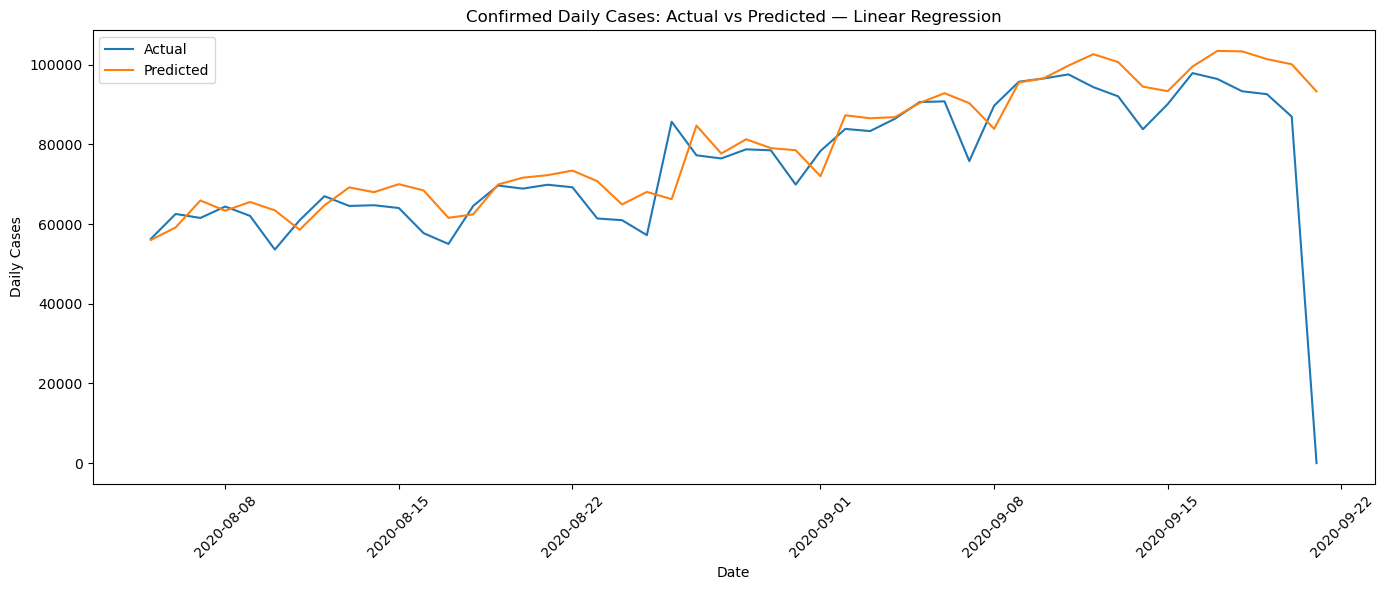

In [31]:
case_test_predictions = best_case_model.predict(X_case_test)
case_test_predictions = np.maximum(case_test_predictions, 0)

plt.figure(figsize=(14, 6))
plt.plot(
    case_test_dates,
    y_case_test.values,
    label="Actual"
)
plt.plot(
    case_test_dates,
    case_test_predictions,
    label="Predicted"
)
plt.title(f"Confirmed Daily Cases: Actual vs Predicted — {best_case_model_name}")
plt.xlabel("Date")
plt.ylabel("Daily Cases")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 22. Deaths — Model Comparison

In [32]:
death_results, death_models = evaluate_models(
    X_death_train,
    X_death_test,
    y_death_train,
    y_death_test
)

display(death_results)

best_death_model_name = death_results.iloc[0]["Model"]
best_death_model = death_models[best_death_model_name]

print("Selected death model:", best_death_model_name)


,Model,MAE,RMSE
0,Linear Regression,89.539290,183.698892
1,Random Forest,218.915208,262.516255
2,Gradient Boosting,244.347973,281.418561


Selected death model: Linear Regression


## 23. Deaths — Actual vs Predicted

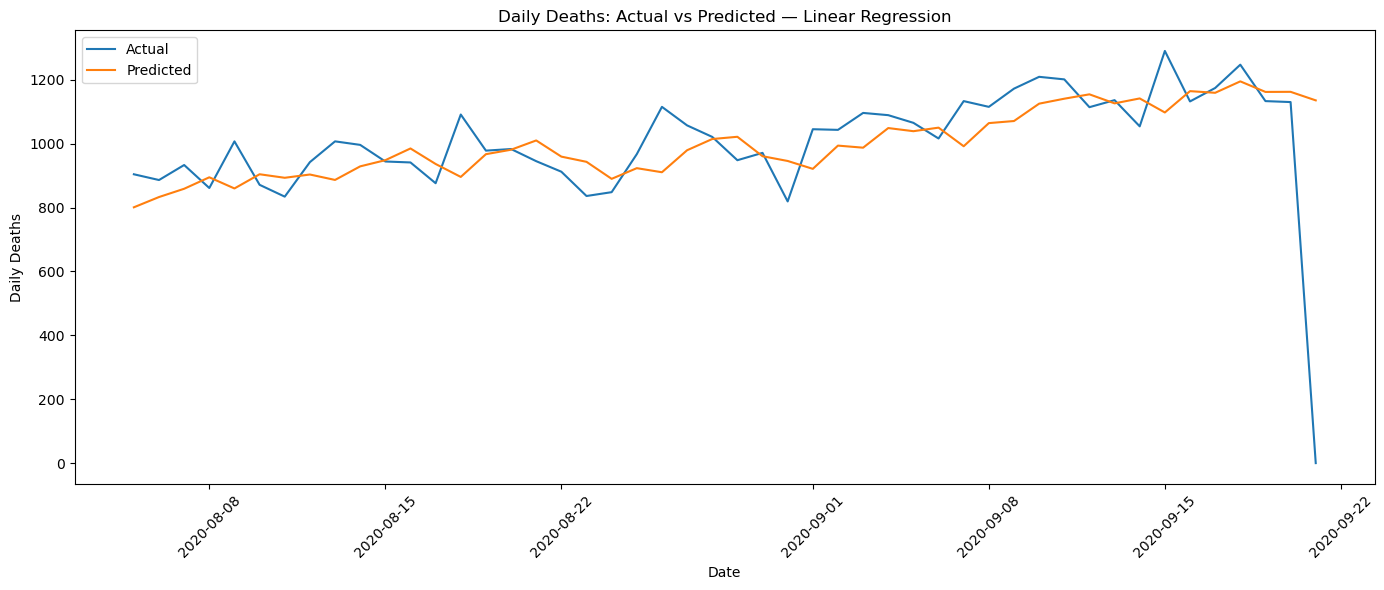

In [33]:
death_test_predictions = best_death_model.predict(X_death_test)
death_test_predictions = np.maximum(death_test_predictions, 0)

plt.figure(figsize=(14, 6))
plt.plot(
    death_test_dates,
    y_death_test.values,
    label="Actual"
)
plt.plot(
    death_test_dates,
    death_test_predictions,
    label="Predicted"
)
plt.title(f"Daily Deaths: Actual vs Predicted — {best_death_model_name}")
plt.xlabel("Date")
plt.ylabel("Daily Deaths")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 24. Model Comparison Report

Lower MAE and RMSE indicate smaller prediction errors on the held-out chronological test period.

The model with the lowest RMSE is selected for the corresponding production-style 7-day forecast. The selection is made separately for confirmed cases and deaths because the two targets can have different error patterns.


In [34]:
model_comparison = pd.DataFrame({
    "Target": ["Confirmed Daily Cases", "Daily Deaths"],
    "Selected Model": [
        best_case_model_name,
        best_death_model_name
    ],
    "Best MAE": [
        case_results.iloc[0]["MAE"],
        death_results.iloc[0]["MAE"]
    ],
    "Best RMSE": [
        case_results.iloc[0]["RMSE"],
        death_results.iloc[0]["RMSE"]
    ]
})

display(model_comparison)


,Target,Selected Model,Best MAE,Best RMSE
0,Confirmed Daily Cases,Linear Regression,7024.739332,15029.032019
1,Daily Deaths,Linear Regression,89.539290,183.698892


# 25. Seven-Day Future Forecast

The selected model is used recursively.

For each future day:
1. Use the latest available lag values.
2. Predict the next daily cases/deaths.
3. Add the prediction to the lag history.
4. Repeat for seven days.

The forecast is an analytical projection from the historical data and should not be interpreted as certainty.


In [35]:
def recursive_forecast(model, history, target_column, days):
    history_values = history[target_column].astype(float).tolist()
    future_values = []

    for _ in range(days):
        row = []

        for lag in LAGS:
            row.append(history_values[-lag])

        X_future = pd.DataFrame(
            [row],
            columns=[f"Lag_{lag}" for lag in LAGS]
        )

        prediction = float(model.predict(X_future)[0])
        prediction = max(prediction, 0)

        future_values.append(prediction)
        history_values.append(prediction)

    return future_values


## 26. Forecast Confirmed Daily Cases

In [36]:
future_case_values = recursive_forecast(
    best_case_model,
    india_confirmed,
    "Daily_Cases",
    FORECAST_DAYS
)

last_date = india_confirmed["Date"].max()

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=FORECAST_DAYS,
    freq="D"
)

case_forecast = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Daily_Cases": future_case_values
})

display(case_forecast)


,Date,Predicted_Daily_Cases
0,2020-09-22,38722.168991
1,2020-09-23,69845.158174
2,2020-09-24,75904.042857
3,2020-09-25,82744.023602
4,2020-09-26,90985.611458
5,2020-09-27,95023.785739
6,2020-09-28,69462.742572


## 27. Forecast Daily Deaths

In [37]:
future_death_values = recursive_forecast(
    best_death_model,
    india_deaths,
    "Daily_Deaths",
    FORECAST_DAYS
)

death_forecast = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Daily_Deaths": future_death_values
})

display(death_forecast)


,Date,Predicted_Daily_Deaths
0,2020-09-22,859.821412
1,2020-09-23,818.470267
2,2020-09-24,712.722720
3,2020-09-25,909.108235
4,2020-09-26,901.350990
5,2020-09-27,912.608642
6,2020-09-28,678.755140


## 28. Seven-Day Forecast Summary

In [38]:
forecast_summary = case_forecast.merge(
    death_forecast,
    on="Date"
)

forecast_summary["Predicted_7_Day_Cases_Total"] = (
    forecast_summary["Predicted_Daily_Cases"].sum()
)

forecast_summary["Predicted_7_Day_Deaths_Total"] = (
    forecast_summary["Predicted_Daily_Deaths"].sum()
)

display(forecast_summary)


,Date,Predicted_Daily_Cases,Predicted_Daily_Deaths,Predicted_7_Day_Cases_Total,Predicted_7_Day_Deaths_Total
0,2020-09-22,38722.168991,859.821412,522687.533393,5792.837406
1,2020-09-23,69845.158174,818.470267,522687.533393,5792.837406
2,2020-09-24,75904.042857,712.722720,522687.533393,5792.837406
3,2020-09-25,82744.023602,909.108235,522687.533393,5792.837406
4,2020-09-26,90985.611458,901.350990,522687.533393,5792.837406
5,2020-09-27,95023.785739,912.608642,522687.533393,5792.837406
6,2020-09-28,69462.742572,678.755140,522687.533393,5792.837406


## 29. Forecast Visualization — Confirmed Cases

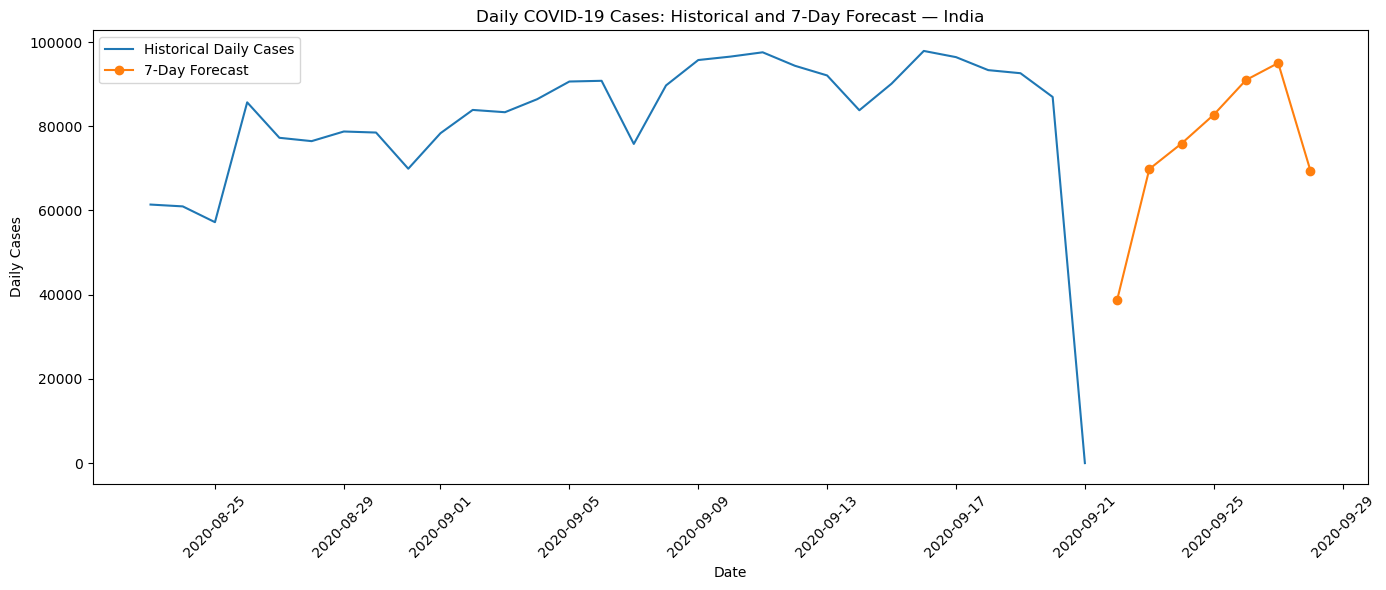

In [39]:
plt.figure(figsize=(14, 6))

recent_cases = india_confirmed.tail(30)

plt.plot(
    recent_cases["Date"],
    recent_cases["Daily_Cases"],
    label="Historical Daily Cases"
)

plt.plot(
    case_forecast["Date"],
    case_forecast["Predicted_Daily_Cases"],
    marker="o",
    label="7-Day Forecast"
)

plt.title(f"Daily COVID-19 Cases: Historical and 7-Day Forecast — {country}")
plt.xlabel("Date")
plt.ylabel("Daily Cases")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 30. Forecast Visualization — Deaths

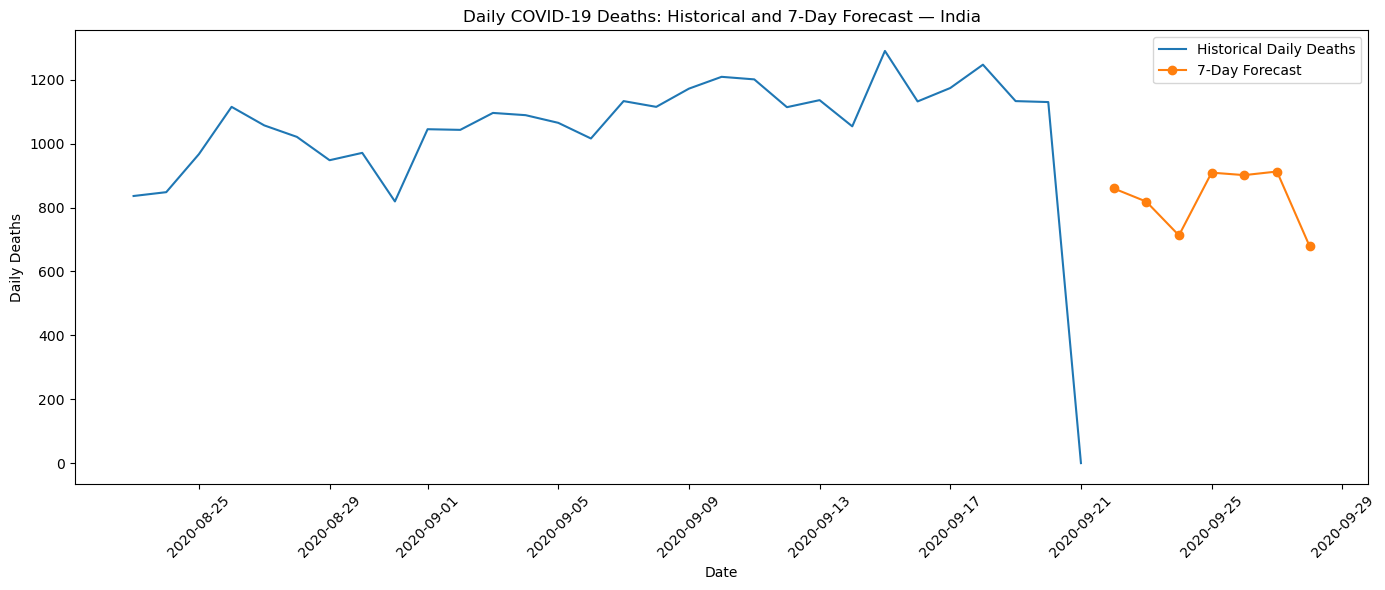

In [40]:
plt.figure(figsize=(14, 6))

recent_deaths = india_deaths.tail(30)

plt.plot(
    recent_deaths["Date"],
    recent_deaths["Daily_Deaths"],
    label="Historical Daily Deaths"
)

plt.plot(
    death_forecast["Date"],
    death_forecast["Predicted_Daily_Deaths"],
    marker="o",
    label="7-Day Forecast"
)

plt.title(f"Daily COVID-19 Deaths: Historical and 7-Day Forecast — {country}")
plt.xlabel("Date")
plt.ylabel("Daily Deaths")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 31. Forecast-Based Preparation Suggestions

The following suggestions are framed as analytical preparation actions rather than guarantees about future disease conditions.

1. Monitor daily confirmed cases and the 7-day moving average.
2. Track the direction of the model's short-term forecast.
3. Use short-term projections as one input for healthcare resource planning.
4. Monitor healthcare capacity, staffing and essential medical supplies.
5. Maintain surveillance systems so changes in reported cases can be identified quickly.
6. Compare future observed values with model predictions and retrain the model when new data becomes available.
7. Use regional/country-level surveillance together with epidemiological and public-health information rather than relying on a machine-learning forecast alone.
8. Maintain flexible preparedness plans because reported COVID-19 data can be revised.


# 32. Challenges Faced and Techniques Used

### Challenge 1 — Wide-format time-series data
The original files store dates as columns.

**Technique:** Melt the data into long format using `pandas.melt()`.

### Challenge 2 — Multiple province/state records
A country can contain multiple geographic records.

**Technique:** Aggregate records by `Country/Region` and `Date`.

### Challenge 3 — Cumulative totals
Cumulative counts are less direct as a daily forecasting target.

**Technique:** Calculate daily changes using `diff()`.

### Challenge 4 — Historical data corrections
Reported totals can occasionally decrease after revisions.

**Technique:** Negative daily differences are clipped to zero for the daily forecasting target.

### Challenge 5 — Time-series data leakage
Random train/test splitting can expose future information during training.

**Technique:** Use chronological 80/20 train-test splitting.

### Challenge 6 — Different model behaviours
A single model may not be best for both cases and deaths.

**Technique:** Compare Linear Regression, Random Forest and Gradient Boosting separately for each target.

### Challenge 7 — Short-term future prediction
Future lag values are not directly available.

**Technique:** Use recursive forecasting, where each prediction becomes part of the lag history for the next forecast day.


# 33. Final Project Results

The notebook reports:

- Dataset structure and quality
- Country-level COVID-19 trends
- Daily cases and deaths
- 7-day moving averages
- Multiple machine-learning model results
- MAE and RMSE for the chronological test set
- Selected model for confirmed cases
- Selected model for deaths
- Seven-day future predictions
- Forecast visualizations
- Preparation suggestions
- Challenges and solutions

The final model choice is determined by the actual test-set RMSE produced when the notebook is executed on the supplied dataset.


In [41]:
print("=" * 70)
print("FINAL PROJECT SUMMARY")
print("=" * 70)

print(f"Selected country: {country}")
print(f"Latest historical date: {latest_date}")
print(f"Forecast horizon: {FORECAST_DAYS} days")

print("\nConfirmed cases:")
print("Selected model:", best_case_model_name)
print("MAE:", round(case_results.iloc[0]["MAE"], 2))
print("RMSE:", round(case_results.iloc[0]["RMSE"], 2))

print("\nDeaths:")
print("Selected model:", best_death_model_name)
print("MAE:", round(death_results.iloc[0]["MAE"], 2))
print("RMSE:", round(death_results.iloc[0]["RMSE"], 2))

print("\n7-day predicted total daily cases:",
      round(case_forecast["Predicted_Daily_Cases"].sum(), 2))

print("7-day predicted total daily deaths:",
      round(death_forecast["Predicted_Daily_Deaths"].sum(), 2))

print("=" * 70)


FINAL PROJECT SUMMARY
Selected country: India
Latest historical date: 2020-09-21 00:00:00
Forecast horizon: 7 days

Confirmed cases:
Selected model: Linear Regression
MAE: 7024.74
RMSE: 15029.03

Deaths:
Selected model: Linear Regression
MAE: 89.54
RMSE: 183.7

7-day predicted total daily cases: 522687.53
7-day predicted total daily deaths: 5792.84


# 34. Conclusion

This project analyzed the Johns Hopkins COVID-19 time-series data and transformed the original wide-format records into country-level time-series data.

India was selected as the forecasting region. Historical confirmed cases, deaths and recovered cases were analyzed, followed by calculation of daily cases/deaths and seven-day moving averages.

Three machine-learning regression models were compared using a chronological test set. The model with the lowest RMSE was selected separately for confirmed cases and deaths.

A seven-day recursive forecast was then generated for both daily confirmed cases and daily deaths. The results can be used as one analytical input for short-term preparedness and resource planning, while actual public-health decisions should also consider current surveillance and epidemiological information.
